# BAB I

# PENDAHULUAN

## 1.1 Business Understanding

Penyakit jantung merupakan salah satu penyakit tidak menular yang menjadi penyebab utama tingginya angka kematian di berbagai negara. Penyakit ini dapat dipengaruhi oleh berbagai faktor, seperti usia, jenis kelamin, tekanan darah, kadar kolesterol, kadar gula darah, denyut jantung maksimum, hingga jenis nyeri dada yang dialami pasien. Apabila faktor-faktor risiko tersebut dapat diidentifikasi lebih awal, maka tenaga medis dapat melakukan tindakan pencegahan maupun penanganan secara lebih cepat sehingga risiko komplikasi dapat diminimalkan.

Seiring berkembangnya teknologi, khususnya pada bidang Machine Learning, proses analisis data kesehatan dapat dilakukan secara lebih efektif dan efisien. Machine Learning mampu mempelajari pola dari data historis pasien untuk membantu proses pengambilan keputusan, salah satunya dalam mengklasifikasikan apakah seorang pasien berpotensi menderita penyakit jantung atau tidak.

Pada proyek ini digunakan algoritma **Support Vector Machine (SVM)** sebagai metode klasifikasi. Algoritma SVM dipilih karena memiliki kemampuan yang baik dalam memisahkan dua kelas data melalui pembentukan hyperplane yang optimal, sehingga banyak digunakan pada berbagai penelitian klasifikasi, termasuk pada bidang kesehatan. Dengan memanfaatkan dataset Heart Disease, diharapkan model yang dibangun mampu memberikan hasil klasifikasi yang akurat dan dapat menjadi referensi dalam membantu proses identifikasi risiko penyakit jantung.

---

## 1.2 Latar Belakang

Penyakit jantung merupakan salah satu masalah kesehatan yang memerlukan perhatian serius karena dapat menyebabkan berbagai komplikasi bahkan kematian apabila tidak ditangani sejak dini. Dalam praktiknya, proses diagnosis penyakit jantung memerlukan analisis terhadap berbagai indikator medis yang dimiliki oleh pasien, seperti tekanan darah, kadar kolesterol, usia, denyut jantung maksimum, serta riwayat nyeri dada. Banyaknya faktor yang harus dipertimbangkan sering kali menyebabkan proses analisis menjadi cukup kompleks.

Machine Learning menawarkan pendekatan yang mampu membantu proses analisis tersebut dengan memanfaatkan data historis pasien untuk membangun model prediksi. Salah satu algoritma yang banyak digunakan dalam permasalahan klasifikasi adalah **Support Vector Machine (SVM)**. Algoritma ini memiliki kemampuan untuk mengklasifikasikan data berdasarkan pemisahan kelas yang optimal sehingga mampu menghasilkan performa yang baik pada berbagai jenis dataset.

Dataset yang digunakan pada penelitian ini merupakan dataset **Heart Disease** yang diperoleh dari sumber terbuka dan terdiri atas berbagai atribut medis yang berkaitan dengan kondisi kesehatan pasien. Sebelum dilakukan proses klasifikasi, dataset terlebih dahulu melalui tahapan preprocessing, seperti pemeriksaan missing value, penghapusan data duplikat, serta standardisasi fitur menggunakan **StandardScaler**. Selanjutnya dibangun model klasifikasi menggunakan algoritma SVM untuk memprediksi kemungkinan seseorang menderita penyakit jantung berdasarkan atribut kesehatan yang dimiliki.

Hasil dari analisis ini diharapkan tidak hanya menghasilkan model klasifikasi dengan performa yang baik, tetapi juga memberikan informasi mengenai faktor-faktor yang berhubungan dengan penyakit jantung sehingga dapat menjadi pendukung dalam proses pengambilan keputusan di bidang kesehatan.

---

## 1.3 Tujuan Analisis

Adapun tujuan dari analisis ini adalah sebagai berikut.

1. Memahami karakteristik dataset penyakit jantung melalui proses eksplorasi data (Exploratory Data Analysis/EDA).
2. Melakukan proses pembersihan dan persiapan data agar dataset siap digunakan dalam proses pemodelan Machine Learning.
3. Membangun model klasifikasi menggunakan algoritma **Support Vector Machine (SVM)** untuk memprediksi kemungkinan seseorang menderita penyakit jantung.
4. Mengevaluasi performa model menggunakan metrik evaluasi **Accuracy**, **Confusion Matrix**, **Classification Report**, dan **ROC Curve**.
5. Menghasilkan insight dari hasil analisis yang dapat membantu memahami hubungan antara faktor kesehatan dengan risiko penyakit jantung.

---

## 1.4 Manfaat Analisis

Manfaat yang diharapkan dari analisis ini adalah sebagai berikut.

### 1. Bagi Bidang Kesehatan

Analisis ini diharapkan dapat membantu tenaga medis dalam memperoleh gambaran awal mengenai risiko penyakit jantung berdasarkan data pasien sehingga dapat menjadi salah satu pendukung dalam proses pengambilan keputusan medis.

### 2. Bagi Pengembangan Teknologi

Analisis ini memberikan contoh penerapan algoritma **Support Vector Machine (SVM)** pada permasalahan klasifikasi di bidang kesehatan sehingga dapat menjadi referensi dalam pengembangan sistem berbasis Machine Learning.


In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# BAB II
# DATA UNDERSTANDING

## 2.1 Load Dataset

Tahap pertama dilakukan dengan membaca dataset Heart Disease menggunakan library Pandas sehingga data dapat diproses pada tahapan berikutnya.

In [2]:
# 1 Load Dataset
df=pd.read_csv("heart-disease.csv")

# Penjelasan Kolom Dataset

| Kolom | Kepanjangan | Deskripsi |
|-------|--------------|------------|
| **age** | Age | Usia pasien dalam satuan tahun. |
| **sex** | Sex | Jenis kelamin pasien (`1 = laki-laki`, `0 = perempuan`). |
| **cp** | Chest Pain Type | Jenis nyeri dada yang dialami pasien. `0 = Typical Angina`, `1 = Atypical Angina`, `2 = Non-anginal Pain`, `3 = Asymptomatic`. |
| **trestbps** | Resting Blood Pressure | Tekanan darah pasien saat istirahat, diukur dalam **mmHg**. |
| **chol** | Serum Cholesterol | Kadar kolesterol serum dalam darah, diukur dalam **mg/dL**. |
| **fbs** | Fasting Blood Sugar | Kadar gula darah puasa. `1 = > 120 mg/dL`, `0 = ≤ 120 mg/dL`. |
| **restecg** | Resting Electrocardiographic Results | Hasil pemeriksaan elektrokardiografi (ECG) saat istirahat. `0 = Normal`, `1 = Kelainan gelombang ST-T`, `2 = Hipertrofi ventrikel kiri`. |
| **thalach** | Maximum Heart Rate Achieved | Denyut jantung maksimum yang berhasil dicapai pasien selama pemeriksaan. |
| **exang** | Exercise Induced Angina | Menunjukkan apakah pasien mengalami angina (nyeri dada) akibat aktivitas fisik. `1 = Ya`, `0 = Tidak`. |
| **oldpeak** | ST Depression Induced by Exercise Relative to Rest | Besarnya penurunan segmen ST pada hasil ECG akibat olahraga dibandingkan kondisi istirahat. |
| **slope** | Slope of the Peak Exercise ST Segment | Kemiringan segmen ST saat puncak aktivitas fisik. `0 = Downsloping`, `1 = Flat`, `2 = Upsloping`. |
| **ca** | Number of Major Vessels Colored by Fluoroscopy | Jumlah pembuluh darah utama yang terlihat melalui pemeriksaan fluoroskopi (nilai 0–3). |
| **thal** | Thalassemia | Hasil pemeriksaan talasemia. `1 = Fixed Defect`, `2 = Normal`, `3 = Reversible Defect`. |
| **target** | Target Variable | Variabel target yang menunjukkan kondisi pasien. `1 = Memiliki penyakit jantung`, `0 = Tidak memiliki penyakit jantung`. |

---

# Ringkasan Dataset

- **Jumlah data:** 303 pasien
- **Jumlah fitur:** 13 fitur prediktor
- **Jumlah target:** 1 fitur (`target`)
- **Jenis permasalahan:** Klasifikasi biner
- **Tujuan analisis:** Membangun model yang dapat memprediksi keberadaan penyakit jantung berdasarkan karakteristik dan hasil pemeriksaan medis pasien.

## 2.3 Menampilkan Dataset

Menampilkan lima data pertama bertujuan untuk memperoleh gambaran awal mengenai isi dataset.

In [3]:
# 2 Data Understanding

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## 2.4 Dimensi Dataset

Tahap ini digunakan untuk mengetahui jumlah baris dan jumlah kolom pada dataset.

In [4]:
df.shape

(303, 14)

## 2.5 Informasi Dataset

Informasi dataset digunakan untuk mengetahui tipe data setiap atribut, jumlah data, serta memastikan tidak terdapat nilai kosong.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


## 2.6 Statistik Deskriptif

Statistik deskriptif digunakan untuk mengetahui karakteristik data seperti nilai rata-rata, minimum, maksimum, dan standar deviasi.

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.366337,9.082101,29.0,47.5,55.0,61.0,77.0
sex,303.0,0.683168,0.466011,0.0,0.0,1.0,1.0,1.0
cp,303.0,0.966997,1.032052,0.0,0.0,1.0,2.0,3.0
trestbps,303.0,131.623762,17.538143,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.264026,51.830751,126.0,211.0,240.0,274.5,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.528053,0.525860,0.0,0.0,1.0,1.0,2.0
thalach,303.0,149.646865,22.905161,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


# BAB III
# DATA PREPARATION

## 3.1 Missing Value

Tahap ini dilakukan untuk memastikan bahwa dataset tidak memiliki data yang hilang sehingga tidak mempengaruhi proses pembangunan model.

In [7]:
# Data Cleaning
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

## 3.2 Duplicate Data

Pemeriksaan data duplikat dilakukan agar tidak terdapat data yang berulang yang dapat mempengaruhi hasil klasifikasi.

In [8]:
print("Jumlah data duplikat :", df.duplicated().sum())

Jumlah data duplikat : 1


## 3.3 Menghapus Data Duplikat

Data yang teridentifikasi sebagai duplikat akan dihapus agar kualitas dataset menjadi lebih baik.

In [9]:
df = df.drop_duplicates()

# BAB IV
# EXPLORATORY DATA ANALYSIS (EDA)

## 4.1 Distribusi Fitur

Histogram digunakan untuk melihat distribusi masing-masing atribut numerik dalam dataset.

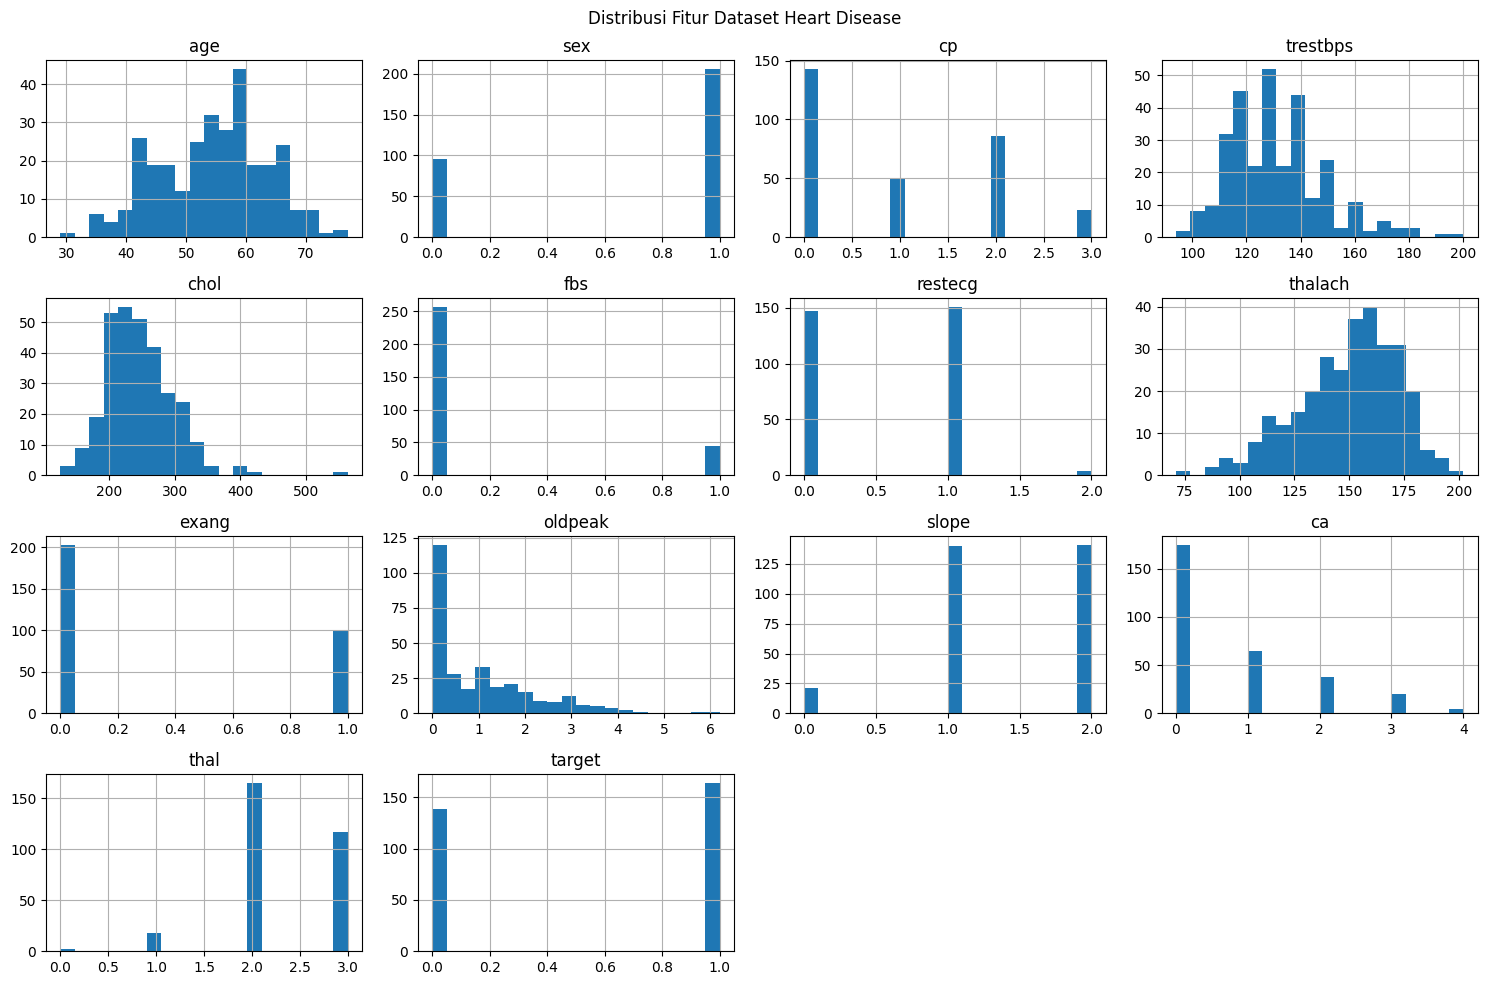

In [10]:
# EDAAAAAA
# Visualisasi distribusi setiap fitur numerik
df.hist(figsize=(15,10), bins=20)
plt.suptitle("Distribusi Fitur Dataset Heart Disease")
plt.tight_layout()
plt.show()

1. Distribusi Usia (Age)
Pada fitur usia, terlihat bahwa sebagian besar pasien berada pada rentang usia sekitar 40 hingga 65 tahun, dengan konsentrasi tertinggi di sekitar usia 55–60 tahun. Hal ini menunjukkan bahwa dataset didominasi oleh pasien usia paruh baya hingga lanjut usia, yang secara umum memang memiliki risiko lebih tinggi terhadap penyakit jantung.

2. Jenis Kelamin (Sex)
Pada fitur jenis kelamin, jumlah pasien laki-laki terlihat lebih banyak dibandingkan pasien perempuan. Temuan ini menunjukkan bahwa dataset memiliki dominasi pasien laki-laki sehingga model akan mempelajari lebih banyak pola dari kelompok tersebut. Selain itu, jenis kelamin berpotensi menjadi salah satu fitur yang membantu proses klasifikasi penyakit jantung.

3. Jenis Nyeri Dada (Chest Pain / CP)
Fitur chest pain memiliki empat kategori dan distribusinya tidak merata. Beberapa kategori memiliki jumlah pasien yang lebih banyak dibandingkan kategori lainnya. Karena nyeri dada merupakan salah satu gejala yang sering dikaitkan dengan penyakit jantung, fitur ini diperkirakan memiliki pengaruh yang cukup besar terhadap hasil prediksi model.

4. Tekanan Darah Istirahat (Trestbps)
Sebagian besar pasien memiliki tekanan darah istirahat pada kisaran 120–140 mmHg. Namun, terdapat beberapa pasien dengan nilai yang cukup tinggi hingga mendekati 200 mmHg. Hal ini menunjukkan adanya variasi kondisi kesehatan pasien dan kemungkinan terdapat nilai ekstrem yang perlu diperhatikan dalam proses analisis.

5. Kolesterol (Chol)
Nilai kolesterol paling banyak berada pada rentang sekitar 200–300 mg/dL. Selain itu, terdapat beberapa pasien dengan kadar kolesterol yang sangat tinggi hingga di atas 400 mg/dL. Kondisi ini menunjukkan bahwa fitur kolesterol memiliki variasi yang cukup besar dan mengandung beberapa nilai yang tergolong ekstrem.

6. Gula Darah Puasa (FBS)
Pada fitur FBS, sebagian besar pasien memiliki nilai 0, sedangkan hanya sebagian kecil yang memiliki nilai 1. Artinya, mayoritas pasien dalam dataset tidak memiliki kadar gula darah puasa yang melebihi batas tertentu. Distribusi ini menunjukkan bahwa kasus gula darah tinggi relatif lebih sedikit dibandingkan kelompok lainnya.

7. Hasil Elektrokardiogram (RestECG)
Fitur RestECG menunjukkan bahwa sebagian besar data berada pada kategori 0 dan 1, sedangkan kategori 2 jumlahnya sangat sedikit. Hal ini mengindikasikan bahwa jenis hasil elektrokardiogram tertentu lebih sering ditemukan pada pasien dalam dataset.

8. Detak Jantung Maksimum (Thalach)
Distribusi detak jantung maksimum terlihat cukup baik dan mendekati bentuk distribusi normal. Nilai yang paling banyak muncul berada pada kisaran 140–170 denyut per menit. Ini menunjukkan bahwa sebagian besar pasien memiliki kemampuan mencapai detak jantung maksimum pada rentang tersebut.

9. Angina Akibat Olahraga (Exang)
Pada fitur Exang, mayoritas pasien memiliki nilai 0, yang berarti tidak mengalami angina akibat olahraga. Meskipun demikian, masih terdapat sejumlah pasien yang memiliki nilai 1 sehingga fitur ini tetap berpotensi memberikan informasi penting bagi model klasifikasi.

10. Oldpeak
Distribusi oldpeak cenderung miring ke kanan (right-skewed). Sebagian besar pasien memiliki nilai yang rendah, tetapi terdapat beberapa pasien dengan nilai yang cukup tinggi hingga di atas 5. Temuan ini menunjukkan adanya variasi kondisi pasien dan kemungkinan terdapat nilai ekstrem pada fitur tersebut.

11. Slope
Pada fitur slope, kategori 1 dan 2 merupakan kategori yang paling banyak muncul, sedangkan kategori 0 jumlahnya relatif sedikit. Hal ini menunjukkan bahwa distribusi kategori pada fitur slope tidak sepenuhnya seimbang.

12. CA
Fitur CA menunjukkan bahwa sebagian besar pasien memiliki nilai 0, sedangkan jumlah pasien dengan nilai yang lebih tinggi semakin sedikit. Distribusi ini memperlihatkan bahwa mayoritas pasien berada pada kategori awal dibandingkan kategori lainnya.

13. Thal
Pada fitur thal, kategori 2 dan 3 mendominasi jumlah data, sementara kategori lainnya memiliki jumlah yang lebih sedikit. Perbedaan distribusi antar kategori ini dapat menjadi informasi yang berguna bagi model dalam membedakan kelas target.

14. Target
Fitur target menunjukkan status apakah pasien memiliki penyakit jantung atau tidak. Dari grafik terlihat bahwa jumlah kedua kelas relatif seimbang. Kondisi ini sangat baik untuk proses klasifikasi karena model dapat mempelajari pola dari kedua kelas secara lebih proporsional dan risiko bias terhadap salah satu kelas menjadi lebih kecil.

## 4.2 Distribusi Target

Visualisasi ini menunjukkan jumlah pasien yang memiliki penyakit jantung dan yang tidak memiliki penyakit jantung.

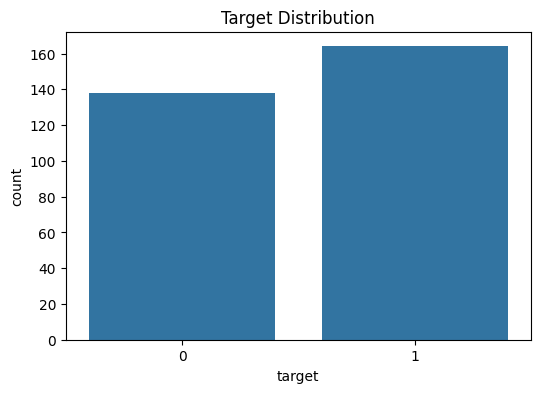

In [12]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x='target'
)

plt.title("Target Distribution")
plt.show()

Grafik ini menunjukkan jumlah pasien yang tidak memiliki penyakit jantung (target = 0) dan yang memiliki penyakit jantung (target = 1). Terlihat bahwa kedua kelas memiliki jumlah yang relatif seimbang, meskipun kelas 1 sedikit lebih banyak. Kondisi ini cukup baik untuk klasifikasi karena model dapat mempelajari kedua kelas dengan proporsional dan risiko bias terhadap salah satu kelas menjadi lebih kecil.

## 4.3 Target Berdasarkan Jenis Kelamin

Visualisasi ini menunjukkan distribusi penyakit jantung berdasarkan jenis kelamin pasien.

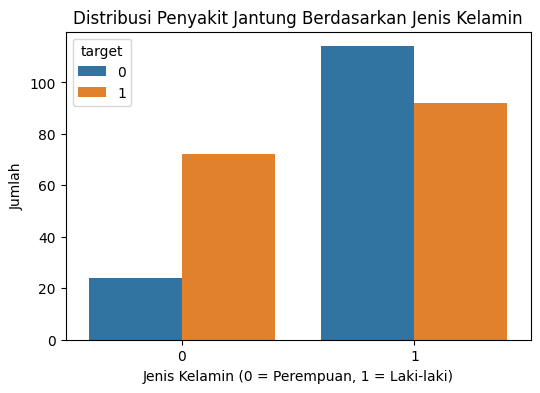

In [13]:
# Distribusi target berdasarkan jenis kelamin
plt.figure(figsize=(6,4))
sns.countplot(x='sex', hue='target', data=df)

plt.title("Distribusi Penyakit Jantung Berdasarkan Jenis Kelamin")
plt.xlabel("Jenis Kelamin (0 = Perempuan, 1 = Laki-laki)")
plt.ylabel("Jumlah")

plt.show()

Pada grafik ini saya membandingkan jenis kelamin dengan status penyakit jantung. Terlihat bahwa jumlah pasien laki-laki lebih banyak dibandingkan perempuan. Selain itu, pada kelompok perempuan, jumlah pasien yang memiliki penyakit jantung lebih banyak daripada yang tidak. Sementara pada kelompok laki-laki, kedua kelas juga cukup banyak meskipun pasien tanpa penyakit jantung sedikit lebih dominan. Hal ini menunjukkan bahwa jenis kelamin memiliki pola distribusi yang berbeda sehingga fitur sex berpotensi membantu model dalam melakukan klasifikasi.

## 4.4 Chest Pain Berdasarkan Target

Visualisasi ini menunjukkan hubungan antara jenis nyeri dada (Chest Pain) dengan status penyakit jantung.

target    0   1
cp             
0       104  39
1         9  41
2        18  68
3         7  16


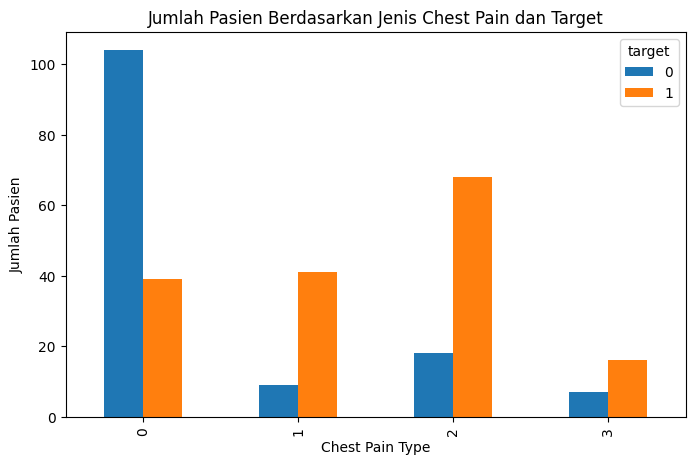

In [14]:
# Jumlah pasien berdasarkan jenis chest pain dan target
cp_target = pd.crosstab(df['cp'], df['target'])

print(cp_target)

cp_target.plot(
    kind='bar',
    figsize=(8,5)
)

plt.title("Jumlah Pasien Berdasarkan Jenis Chest Pain dan Target")
plt.xlabel("Chest Pain Type")
plt.ylabel("Jumlah Pasien")

plt.show()

Grafik ini memperlihatkan hubungan antara jenis nyeri dada (cp) dan status penyakit jantung. Terlihat bahwa kategori cp = 0 didominasi oleh pasien tanpa penyakit jantung, sedangkan kategori cp = 2 justru memiliki banyak pasien dengan penyakit jantung. Kategori lainnya juga menunjukkan pola yang berbeda. Dari sini dapat disimpulkan bahwa jenis nyeri dada memiliki hubungan yang cukup kuat dengan target dan kemungkinan menjadi salah satu fitur yang paling berpengaruh dalam model.

## 4.5 Korelasi Antar Variabel

Heatmap digunakan untuk mengetahui hubungan antar atribut pada dataset.

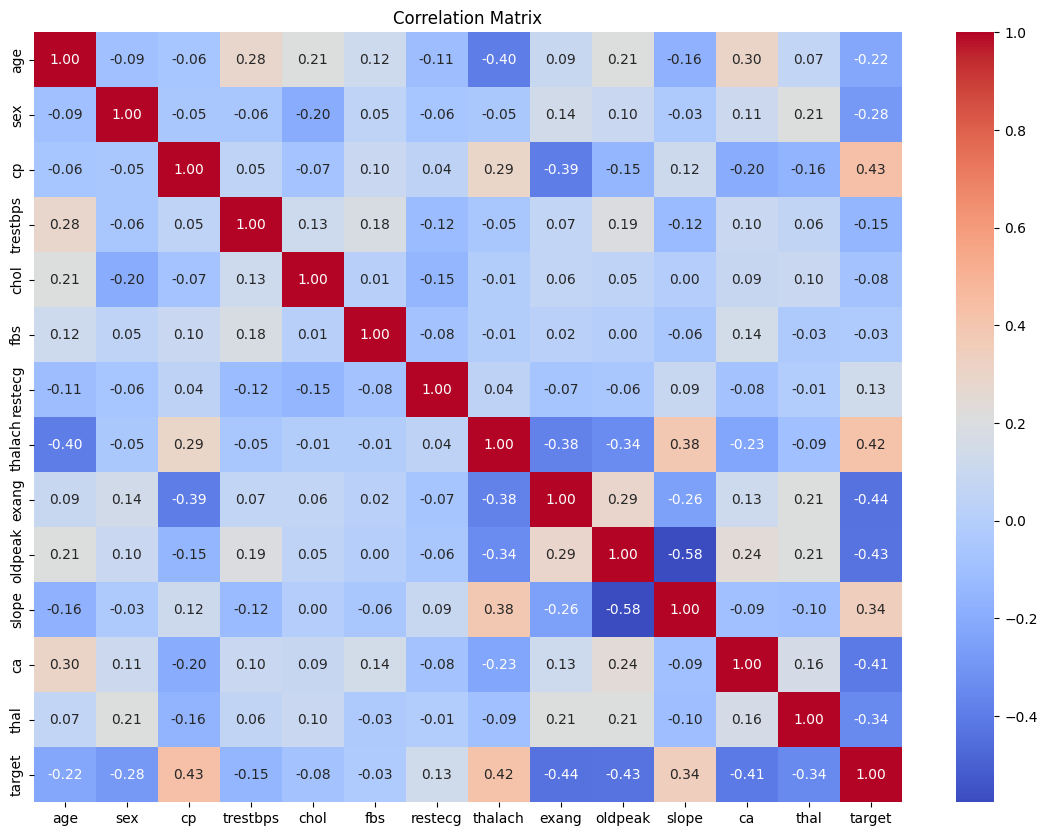

In [15]:
plt.figure(figsize=(14,10))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Matrix")
plt.show()

Heatmap ini digunakan untuk melihat hubungan antar variabel. Warna merah menunjukkan korelasi positif, sedangkan warna biru menunjukkan korelasi negatif. Dari grafik terlihat bahwa fitur cp memiliki korelasi positif sekitar 0,43 terhadap target, thalach sekitar 0,42, dan slope sekitar 0,34. Sementara itu, exang, oldpeak, ca, dan thal memiliki korelasi negatif terhadap target. Ini berarti fitur-fitur tersebut memiliki keterkaitan yang cukup kuat dengan status penyakit jantung.

In [16]:
# Korelasi fitur terhadap target
correlation = df.corr()['target'].sort_values(ascending=False)

print(correlation)

target      1.000000
cp          0.432080
thalach     0.419955
slope       0.343940
restecg     0.134874
fbs        -0.026826
chol       -0.081437
trestbps   -0.146269
age        -0.221476
sex        -0.283609
thal       -0.343101
ca         -0.408992
oldpeak    -0.429146
exang      -0.435601
Name: target, dtype: float64


## 4.6 Business Insight

Pada tahap ini dilakukan analisis terhadap hasil eksplorasi data sehingga diperoleh informasi yang dapat digunakan sebagai dasar pengambilan keputusan.

target
1    54.304636
0    45.695364
Name: proportion, dtype: float64


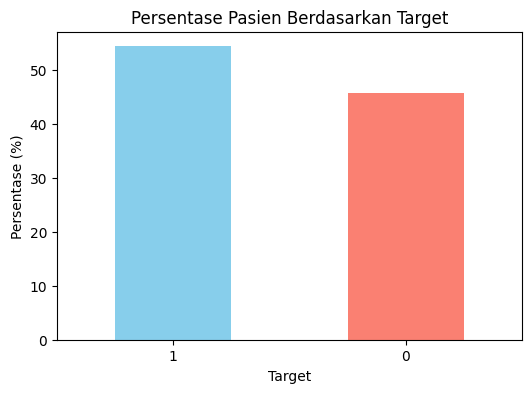

In [17]:
# Business Insight
# 1 Persentase pasien berdasarkan target
target_percentage = df['target'].value_counts(normalize=True) * 100

print(target_percentage)

plt.figure(figsize=(6,4))
target_percentage.plot(kind='bar', color=['skyblue','salmon'])

plt.title("Persentase Pasien Berdasarkan Target")
plt.xlabel("Target")
plt.ylabel("Persentase (%)")

plt.xticks(rotation=0)
plt.show()

target
0    56.601449
1    52.585366
Name: age, dtype: float64


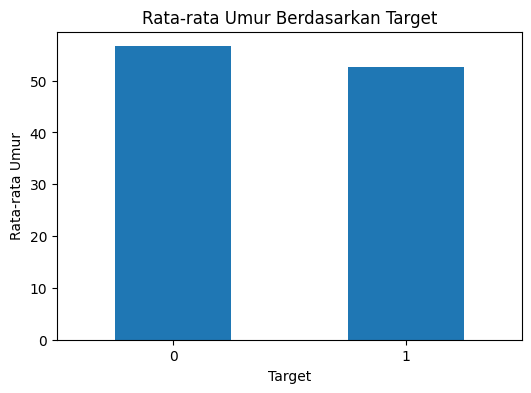

In [18]:
# 2 Rata-rata umur berdasarkan target
age_target = df.groupby('target')['age'].mean()

print(age_target)

plt.figure(figsize=(6,4))
age_target.plot(kind='bar')

plt.title("Rata-rata Umur Berdasarkan Target")
plt.xlabel("Target")
plt.ylabel("Rata-rata Umur")

plt.xticks(rotation=0)
plt.show()

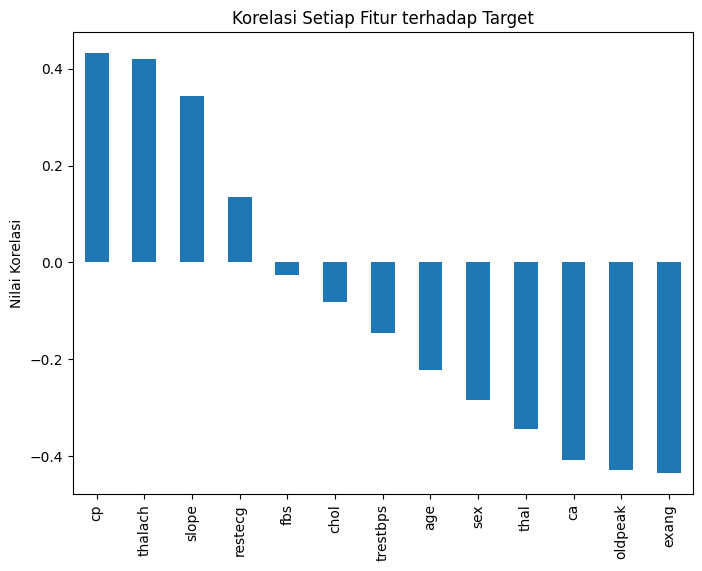

In [21]:
# 5 Korelasi Fitur Terhadap Target
plt.figure(figsize=(8,6))

correlation.drop('target').plot(kind='bar')

plt.title("Korelasi Setiap Fitur terhadap Target")

plt.ylabel("Nilai Korelasi")

plt.show()

Berdasarkan analisis korelasi, fitur Chest Pain (cp) dan Maximum Heart Rate (thalach) memiliki hubungan positif terhadap target, sedangkan Oldpeak dan Number of Major Vessels (ca) memiliki hubungan negatif. Hal ini menunjukkan bahwa variabel-variabel tersebut berpotensi menjadi faktor penting dalam proses klasifikasi penyakit jantung.

In [22]:
X = df.drop(columns='target')
y = df['target']

# BAB V
# PEMBANGUNAN MODEL

## 5.1 Data Preparation

Tahap ini meliputi pemisahan atribut dan target, pembagian data latih dan data uji, serta standardisasi data menggunakan StandardScaler.

In [23]:
# Data Preparation
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [24]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## 5.2 Model Building

Model klasifikasi dibangun menggunakan algoritma Support Vector Machine (SVM) dengan kernel Radial Basis Function (RBF).

In [25]:
# Model Building
svm_model = SVC(
    kernel='rbf',
    C=1,
    gamma='scale',
    probability=True,
    random_state=42
)

svm_model.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


# BAB VI
# MODEL EVALUATION

## 6.1 Prediction

Model yang telah dilatih digunakan untuk melakukan prediksi terhadap data uji.

In [26]:
# Prediction
y_pred = svm_model.predict(X_test)

## 6.2 Accuracy

Accuracy digunakan untuk mengetahui tingkat ketepatan model dalam melakukan klasifikasi.

In [27]:
# Accuracy

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy : {accuracy:.4f}")
print(f"Accuracy : {accuracy*100:.2f}%")

Accuracy : 0.8361
Accuracy : 83.61%


## 6.3 Training Accuracy

Training Accuracy menunjukkan performa model terhadap data latih.

In [28]:
# Training Accuracy

training_accuracy = svm_model.score(X_train, y_train)

print(f"Training Accuracy : {training_accuracy:.4f}")
print(f"Training Accuracy : {training_accuracy*100:.2f}%")

Training Accuracy : 0.9087
Training Accuracy : 90.87%


## 6.4 Testing Accuracy

Testing Accuracy menunjukkan performa model terhadap data uji.

In [29]:
# Testing Accuracy

testing_accuracy = svm_model.score(X_test, y_test)

print(f"Testing Accuracy : {testing_accuracy:.4f}")
print(f"Testing Accuracy : {testing_accuracy*100:.2f}%")

Testing Accuracy : 0.8361
Testing Accuracy : 83.61%


## 6.5 Confusion Matrix

Confusion Matrix digunakan untuk mengetahui jumlah prediksi yang benar maupun salah pada setiap kelas.

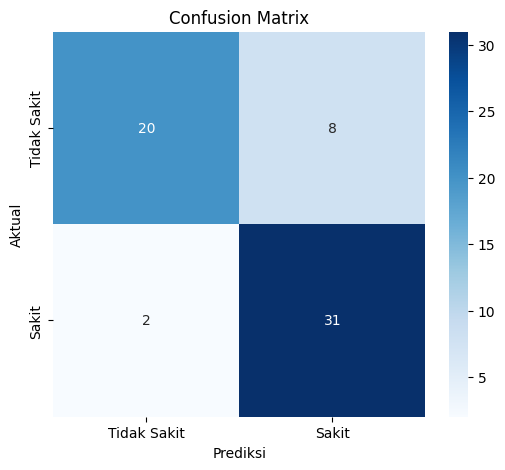

In [30]:
# Confusion Matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Tidak Sakit', 'Sakit'],
    yticklabels=['Tidak Sakit', 'Sakit']
)

plt.title("Confusion Matrix")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")

plt.show()

Confusion Matrix digunakan untuk melihat jumlah prediksi yang benar dan salah. Dari grafik terlihat bahwa model berhasil memprediksi 20 pasien tidak sakit dengan benar (True Negative) dan 31 pasien sakit dengan benar (True Positive). Selain itu, terdapat 8 pasien yang sebenarnya tidak sakit tetapi diprediksi sakit (False Positive), dan 2 pasien yang sebenarnya sakit tetapi diprediksi tidak sakit (False Negative).

Dalam kasus penyakit jantung,kami lebih memperhatikan False Negative karena kondisi ini berarti pasien yang sebenarnya sakit justru diprediksi sehat. Pada model ini, jumlah False Negative hanya 2, sehingga model cukup baik dalam mendeteksi pasien yang sakit.

## 6.6 Classification Report

Classification Report memberikan informasi mengenai nilai Precision, Recall, F1-Score, dan Support.

In [31]:
# Classification Report

from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.91      0.71      0.80        28
           1       0.79      0.94      0.86        33

    accuracy                           0.84        61
   macro avg       0.85      0.83      0.83        61
weighted avg       0.85      0.84      0.83        61

